In [8]:
import os
from google.colab import drive
drive.mount('/content/drive')
os.makedirs("/content/drive/MyDrive/crop_model", exist_ok=True)
SAVE_DIR = "/content/drive/MyDrive/crop_model"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
!unzip -o -q "/content/drive/MyDrive/Colab Notebooks/train.zip" -d /content/train
!unzip -o -q "/content/drive/MyDrive/Colab Notebooks/archive.zip" -d /content/archive

In [16]:
import os, re, json, random, numpy as np, tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# ====== EDIT THESE ======
DATA_ROOTS = ["/content/train", "/content/archive"]   # folders that contain the class folders
MODEL_NAME = "EfficientNetB3"                          # or "EfficientNetB3"
IMG_SIZE   = 300                                      # use 300 for B3
BATCH      = 16
# ========================

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

def norm(s): return re.sub(r'[^a-z0-9]', '', s.lower())

# normalized folder name -> (clean English name, Marathi)
LABELS = {
 "bacterialclanker": ("Bacterial_canker", "जिवाणू कर्पा (Jivanu Karpa)"),
 "bacterialcanker":  ("Bacterial_canker", "जिवाणू कर्पा (Jivanu Karpa)"),
 "bacterialspot":    ("Bacterial_spot", "जिवाणू ठिपके (Jivanu Thipke)"),
 "chilliwhitefly":   ("Chilli_Whitefly", "पांढरी माशी (Pandhari Mashi)"),
 "chilliyellowish":  ("Chilli_Yellowish", "मिरची पिवळी पडणे (Mirchi Pivali Padane)"),
 "chillibacterialspot": ("Chilli_Bacterial_Spot", "मिरची जिवाणू ठिपके (Mirchi Jivanu Thipke)"),
 "chilllianthracnos": ("Chilli_Anthracnose", "फळ सड / कूर्पा (Phalsad / Karpa)"),
 "chilliAnthracnos".lower(): ("Chilli_Anthracnose", "फळ सड / कूर्पा (Phalsad / Karpa)"),
 "chillidampingoff": ("Chilli_Damping_Off", "मर रोग (Mar Rog)"),
 "chillileafcurlvirus": ("Chilli_Leaf_Curl_Virus", "चुरडा-मुरडा / बोकड्या (Churda-Murda / Bokadya)"),
 "chillileafspot":   ("Chilli_Leaf_Spot", "मिरची पान ठिपके (Mirchi Pan Thipke)"),
 "chilliveinalmottlevirus": ("Chilli_Veinal_Mottle_Virus", "शिरा पिवळ्या पडणे (Shira Pivalya Padane)"),
 "chillihealthy":    ("Chilli_healthy", "निरोगी मिरची (Nirogi Mirchi)"),
 "earlyblight":      ("Early_blight", "लवकर येणारा करपा (Lavkar Karpa)"),
 "lateblight":       ("Late_blight", "उशिरा येणारा करपा (Ushira Karpa)"),
 "leafcurl":         ("Leaf_curl", "चुरडा-मुरडा (Churda-Murda)"),
 "septorialeafspot": ("Septoria_leaf_spot", "सेप्टोरिया ठिपके (Septoria Thipke)"),
 "spottedwilt":      ("Spotted_Wilt", "ठिपकेदार सुकवा (Thipkedar Sukva)"),
 "tomatomosaicvirus":("Tomato_mosaic_virus", "टोमॅटो मोझॅक (Tomato Mosaic)"),
 "healthy":          ("Tomato_healthy", "निरोगी पीक (Nirogi Peek)"),
}

In [17]:
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
paths, names = [], []
seen = set()
skipped = {}

for root in DATA_ROOTS:
    for dirpath, dirnames, filenames in os.walk(root):
        imgs = [f for f in filenames if Path(f).suffix.lower() in EXT]
        if not imgs: continue
        key = norm(os.path.basename(dirpath))
        if key in LABELS:
            eng = LABELS[key][0]
            for f in imgs:
                p = os.path.join(dirpath, f)
                if p not in seen:
                    seen.add(p); paths.append(p); names.append(eng)
        else:
            skipped[dirpath] = len(imgs)

if skipped:
    print("⚠️ Folders with images that did NOT match a label (ignored):")
    for d, n in skipped.items(): print(f"  {n:6d}  {d}")

class_names = sorted(set(names))
marathi = {LABELS[k][0]: LABELS[k][1] for k in LABELS}
cls_idx = {c: i for i, c in enumerate(class_names)}
y = np.array([cls_idx[n] for n in names]); X = np.array(paths)

print(f"\n{len(X)} images, {len(class_names)} classes")
for c in class_names: print(f"{c:30s} {int((y==cls_idx[c]).sum()):6d}")


28561 images, 18 classes
Bacterial_canker                   20
Bacterial_spot                   4455
Chilli_Anthracnose                527
Chilli_Bacterial_Spot            1629
Chilli_Damping_Off                188
Chilli_Leaf_Curl_Virus            520
Chilli_Leaf_Spot                  520
Chilli_Veinal_Mottle_Virus       2020
Chilli_Whitefly                   520
Chilli_Yellowish                  520
Chilli_healthy                   1940
Early_blight                     2455
Late_blight                      3113
Leaf_curl                        2039
Septoria_leaf_spot               2882
Spotted_Wilt                        9
Tomato_healthy                   3051
Tomato_mosaic_virus              2153


In [18]:
from PIL import Image
from tqdm import tqdm

def img_key(path):
    # tiny fingerprint of the image; flips give the same key
    img = Image.open(path).convert("L").resize((17, 16))
    a = np.asarray(img, dtype=np.int16)
    keys = []
    for v in (a, a[:, ::-1], a[::-1, :], a[::-1, ::-1]):
        bits = (v[:, 1:] > v[:, :-1]).flatten()
        keys.append("".join("1" if b else "0" for b in bits))
    return min(keys)

seen_keys, keep = set(), []
for i, (p, n) in enumerate(tqdm(zip(X, names), total=len(X))):
    try:
        k = (img_key(p), n)
    except Exception:
        continue                      # skip broken/unreadable images
    if k not in seen_keys:
        seen_keys.add(k); keep.append(i)

print(f"Removed {len(X) - len(keep)} duplicate/broken images")
X = X[keep]; y = y[keep]
for c in class_names: print(f"{c:30s} {int((y==cls_idx[c]).sum()):6d}")

100%|██████████| 28561/28561 [05:15<00:00, 90.53it/s] 

Removed 4749 duplicate/broken images
Bacterial_canker                    9
Bacterial_spot                   3825
Chilli_Anthracnose                408
Chilli_Bacterial_Spot            1008
Chilli_Damping_Off                150
Chilli_Leaf_Curl_Virus            467
Chilli_Leaf_Spot                  485
Chilli_Veinal_Mottle_Virus       1610
Chilli_Whitefly                   488
Chilli_Yellowish                  434
Chilli_healthy                   1830
Early_blight                     1246
Late_blight                      2737
Leaf_curl                        2039
Septoria_leaf_spot               2563
Spotted_Wilt                        9
Tomato_healthy                   2584
Tomato_mosaic_virus              1920


In [19]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te   = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

# --- oversample small classes in TRAIN only ---
TARGET = 300
rng = np.random.default_rng(SEED)
extra_X, extra_y = [], []
for c in range(len(class_names)):
    idx = np.where(y_tr == c)[0]
    if 0 < len(idx) < TARGET:
        pick = rng.choice(idx, TARGET - len(idx), replace=True)
        extra_X += list(X_tr[pick]); extra_y += list(y_tr[pick])
X_tr = np.concatenate([X_tr, np.array(extra_X)]) if extra_X else X_tr
y_tr = np.concatenate([y_tr, np.array(extra_y)]) if extra_y else y_tr
print("train/val/test:", len(X_tr), len(X_va), len(X_te))

AUTOTUNE = tf.data.AUTOTUNE
def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_ds(Xs, ys, training):
    ds = tf.data.Dataset.from_tensor_slices((Xs, ys))
    if training: ds = ds.shuffle(len(Xs), seed=SEED)
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(X_tr, y_tr, True), make_ds(X_va, y_va, False), make_ds(X_te, y_te, False)

cw = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=y_tr)
class_weight = dict(enumerate(np.clip(cw, 0.3, 5.0)))

train/val/test: 19815 2381 2382


In [20]:
from tensorflow.keras import layers, models

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25, fill_mode="reflect"),
    layers.RandomZoom((-0.3, 0.5), fill_mode="reflect"),
    layers.RandomTranslation(0.2, 0.2, fill_mode="reflect"),
    layers.RandomContrast(0.3),
    layers.RandomBrightness(0.3, value_range=(0, 255)),
], name="augment")

base = getattr(tf.keras.applications, MODEL_NAME)(
    include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False

inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)                       # EfficientNet rescales internally (expects 0-255)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [21]:

import os
from google.colab import drive
drive.mount('/content/drive')
SAVE_DIR = "/content/drive/MyDrive/crop_model"
os.makedirs(SAVE_DIR, exist_ok=True)

ckpt1 = tf.keras.callbacks.ModelCheckpoint(
    f"{SAVE_DIR}/stage1_best.keras", monitor="val_accuracy", save_best_only=True)

h1 = model.fit(train_ds, validation_data=val_ds, epochs=10,
               class_weight=class_weight, callbacks=[ckpt1])

model.save(f"{SAVE_DIR}/stage1.keras")
print("Saved to Drive:", os.listdir(SAVE_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/10
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 238s 175ms/step - accuracy: 0.5766 - loss: 1.3335 - val_accuracy: 0.7010 - val_loss: 0.9382
Epoch 2/10
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 203s 164ms/step - accuracy: 0.6641 - loss: 0.9844 - val_accuracy: 0.7556 - val_loss: 0.8190
Epoch 3/10
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 202s 163ms/step - accuracy: 0.6809 - loss: 0.9161 - val_accuracy: 0.7190 - val_loss: 0.8934
Epoch 4/10
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 202s 163ms/step - accuracy: 0.6849 - loss: 0.8900 - val_accuracy: 0.7501 - val_loss: 0.8044
Epoch 5/10
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 202s 163ms/step - accuracy: 0.6966 - loss: 0.8844 - val_accuracy: 0.7669 - val_loss: 0.7550
Epoch 6/10
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 201s 162ms/step - accuracy: 0.6964 - loss: 0.8762 - val_accuracy: 0.7551 - val_loss: 0.7658
Epoch 7/10
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 203s 164ms/step - accurac

In [22]:
import os
from google.colab import drive
from tensorflow.keras import layers

# make sure Drive is mounted and the save folder exists (safe to run again)
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount('/content/drive')
SAVE_DIR = "/content/drive/MyDrive/crop_model"
os.makedirs(SAVE_DIR, exist_ok=True)

# unfreeze only the top ~60 layers of EfficientNet (BatchNorm layers stay frozen)
base.trainable = True
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
for layer in base.layers[:-60]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cbs = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-6),
    # saves to Drive every time validation accuracy improves
    tf.keras.callbacks.ModelCheckpoint(f"{SAVE_DIR}/best_model.keras",
                                       monitor="val_accuracy", save_best_only=True),
]

h2 = model.fit(train_ds, validation_data=val_ds, epochs=25,
               class_weight=class_weight, callbacks=cbs)

print("Files on Drive:", os.listdir(SAVE_DIR))

Epoch 1/25
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 252s 189ms/step - accuracy: 0.7659 - loss: 0.6209 - val_accuracy: 0.8459 - val_loss: 0.5317 - learning_rate: 1.0000e-04
Epoch 2/25
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 262s 190ms/step - accuracy: 0.8174 - loss: 0.4378 - val_accuracy: 0.8585 - val_loss: 0.4532 - learning_rate: 1.0000e-04
Epoch 3/25
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 235s 190ms/step - accuracy: 0.8414 - loss: 0.3623 - val_accuracy: 0.8719 - val_loss: 0.3871 - learning_rate: 1.0000e-04
Epoch 4/25
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 237s 191ms/step - accuracy: 0.8537 - loss: 0.3298 - val_accuracy: 0.8921 - val_loss: 0.3223 - learning_rate: 1.0000e-04
Epoch 5/25
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 235s 190ms/step - accuracy: 0.8630 - loss: 0.2832 - val_accuracy: 0.8963 - val_loss: 0.3045 - learning_rate: 1.0000e-04
Epoch 6/25
1239/1239 ━━━━━━━━━━━━━━━━━━━━ 263s 190ms/step - accuracy: 0.8725 - loss: 0.2645 - val_accuracy: 0.9017 - val_loss: 0.2643 - learning_rate: 1.0000e-04
Epoch 7/25
1239/1239 ━━━━━━━

149/149 ━━━━━━━━━━━━━━━━━━━━ 21s 141ms/step - accuracy: 0.9295 - loss: 0.1478
Test accuracy: 92.95%
149/149 ━━━━━━━━━━━━━━━━━━━━ 28s 163ms/step
                            precision    recall  f1-score   support

          Bacterial_canker      1.000     1.000     1.000         1
            Bacterial_spot      0.985     0.671     0.798       383
        Chilli_Anthracnose      0.951     0.975     0.963        40
     Chilli_Bacterial_Spot      0.483     1.000     0.652       101
        Chilli_Damping_Off      0.938     1.000     0.968        15
    Chilli_Leaf_Curl_Virus      0.827     0.935     0.878        46
          Chilli_Leaf_Spot      0.941     1.000     0.970        48
Chilli_Veinal_Mottle_Virus      1.000     1.000     1.000       161
           Chilli_Whitefly      0.980     1.000     0.990        49
          Chilli_Yellowish      0.947     0.837     0.889        43
            Chilli_healthy      0.978     0.962     0.970       183
              Early_blight      0.945  

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


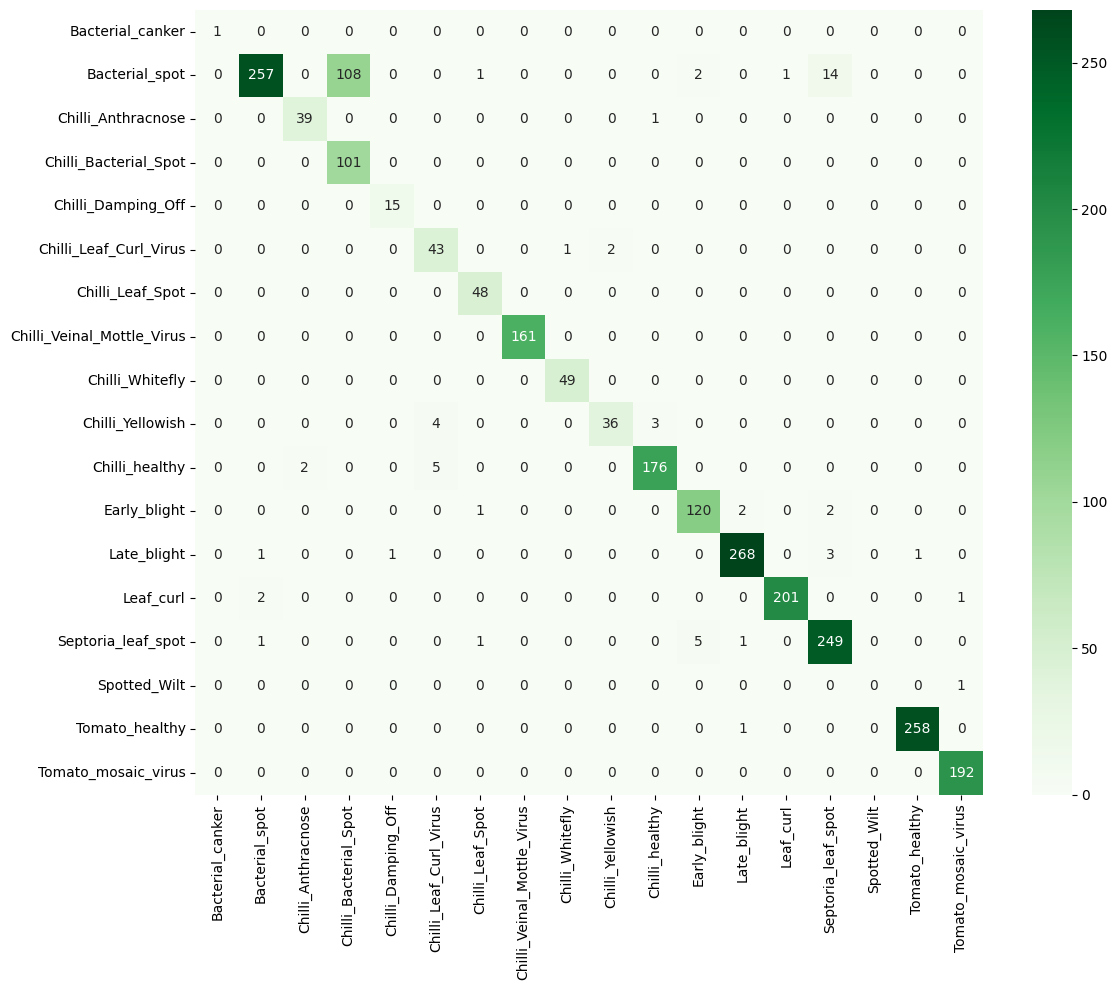

In [23]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns
import os

# Safely retrieve or load the model if the variable is missing from the namespace
if 'model' not in globals():
    print("'model' is not defined in memory. Attempting to load saved model from disk...")
    for model_file in ["best_model.keras", "crop_disease_model.keras"]:
        if os.path.exists(model_file):
            import tensorflow as tf
            model = tf.keras.models.load_model(model_file)
            print(f"Successfully loaded model from {model_file}!")
            break
    else:
        raise NameError("No trained 'model' variable in memory, and no saved model file found on disk. Please run the model definition and training cells first.")

loss, acc = model.evaluate(test_ds)
print(f"Test accuracy: {acc*100:.2f}%")

y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_te, y_pred, target_names=class_names, digits=3))

plt.figure(figsize=(12, 10))
sns.heatmap(confusion_matrix(y_te, y_pred), annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

In [24]:
import os, json
from google.colab import drive, files
drive.mount('/content/drive')
SAVE_DIR = "/content/drive/MyDrive/crop_model"
os.makedirs(SAVE_DIR, exist_ok=True)

model_path = f"{SAVE_DIR}/crop_disease_model.keras"
labels_path = f"{SAVE_DIR}/class_names.json"

model.save(model_path)
with open(labels_path, "w", encoding="utf-8") as f:
    json.dump({"classes": class_names, "marathi": {c: marathi[c] for c in class_names}},
              f, ensure_ascii=False, indent=2)

# verify the files really exist and are not empty
for p in (model_path, labels_path):
    print("✅" if os.path.exists(p) and os.path.getsize(p) > 0 else "❌",
          p, f"{os.path.getsize(p)/1e6:.1f} MB" if os.path.exists(p) else "")
print("TF version:", tf.__version__)

# second copy straight to your PC
files.download(model_path)
files.download(labels_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ /content/drive/MyDrive/crop_model/crop_disease_model.keras 86.7 MB
✅ /content/drive/MyDrive/crop_model/class_names.json 0.0 MB
TF version: 2.21.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving kharab toma.jpg to kharab toma.jpg
 kharab toma.jpg


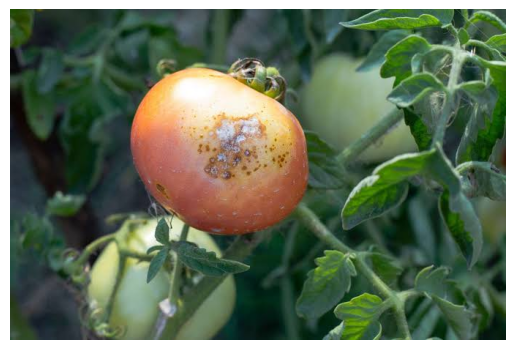

निकाल (Result): जिवाणू कर्पा (Jivanu Karpa)
खात्री (Confidence): 85.7%


In [25]:
from google.colab import files
import matplotlib.pyplot as plt

def predict_image(img_path, min_conf=0.8):
    img = tf.keras.utils.load_img(img_path)
    w, h = img.size
    crops = [img]
    for frac in (0.7, 0.5):
        cw, ch = int(w*frac), int(h*frac)
        for (x, y) in [((w-cw)//2, (h-ch)//2), (0, 0), (w-cw, 0), (0, h-ch), (w-cw, h-ch)]:
            crops.append(img.crop((x, y, x+cw, y+ch)))
    batch = np.stack([tf.keras.utils.img_to_array(c.resize((IMG_SIZE, IMG_SIZE))) for c in crops])
    probs = model.predict(batch, verbose=0).mean(axis=0)

    plt.imshow(img); plt.axis("off"); plt.show()
    best = probs.argmax()
    print(f"निकाल (Result): {marathi[class_names[best]]}")
    print(f"खात्री (Confidence): {probs[best]*100:.1f}%")
    if probs[best] < min_conf:
        print("⚠️ खात्री नाही — कृपया जवळून स्पष्ट फोटो घ्या (Not sure, please take a close, clear photo)")

uploaded = files.upload()
for name in uploaded.keys():
    print("=" * 50, "\n", name)
    predict_image(name)